# Behavioral Analysis

This notebook analyzes normal and unusual user behavior in CERT R1.

The system creates a behavioral profile for every user-day and compares activity against:
- Personal historical behavior
- Role-level behavior

These deviations are later used by the anomaly detection system.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = os.path.abspath("..")
PROCESSED_DIR = os.path.join(BASE_DIR, "dataset", "processed")

path = os.path.join(PROCESSED_DIR, "ML_Dataset.csv")
df = pd.read_csv(path)

df["day"] = pd.to_datetime(df["day"])

print("Records:", len(df))
print("Columns:", len(df.columns))

Records: 334905
Columns: 86


In [2]:
behavior_columns = [
    "login_count",
    "logout_count",
    "after_hours_login",
    "unique_pcs",
    "work_duration_minutes",
    "usb_connect_count",
    "usb_disconnect_count",
    "after_hours_usb",
    "web_activity_count",
    "unique_domains",
    "after_hours_web"
]

display(df[behavior_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
login_count,334905.0,1.406002,0.886062,0.0,1.000000,1.00,2.000000,18.00
logout_count,334905.0,1.130774,0.755276,1.0,1.000000,1.00,1.000000,17.00
after_hours_login,334905.0,0.289240,0.884184,0.0,0.000000,0.00,0.000000,19.00
unique_pcs,334905.0,1.121915,0.758891,1.0,1.000000,1.00,1.000000,18.00
work_duration_minutes,334905.0,573.469114,103.040094,0.0,530.033333,549.85,608.583333,1439.15
usb_connect_count,334905.0,0.103062,0.306992,0.0,0.000000,0.00,0.000000,2.00
usb_disconnect_count,334905.0,0.093017,0.293230,0.0,0.000000,0.00,0.000000,2.00
after_hours_usb,334905.0,0.011323,0.140691,0.0,0.000000,0.00,0.000000,4.00
web_activity_count,334905.0,10.306400,33.466867,0.0,0.000000,1.00,5.000000,647.00
unique_domains,334905.0,5.468228,13.451039,0.0,0.000000,1.00,5.000000,240.00


In [3]:
deviation_columns = [
    "personal_anomaly_strength",
    "role_anomaly_strength",
    "behavioral_deviation_score"
]

display(df[deviation_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
personal_anomaly_strength,334905.0,0.283051,0.279355,0.003318,0.125956,0.202496,0.340623,5.531274
role_anomaly_strength,334905.0,0.509892,0.395981,0.081489,0.313067,0.371534,0.513096,10.000000
behavioral_deviation_score,334905.0,0.351113,0.297819,0.047900,0.192769,0.257271,0.382614,8.027090


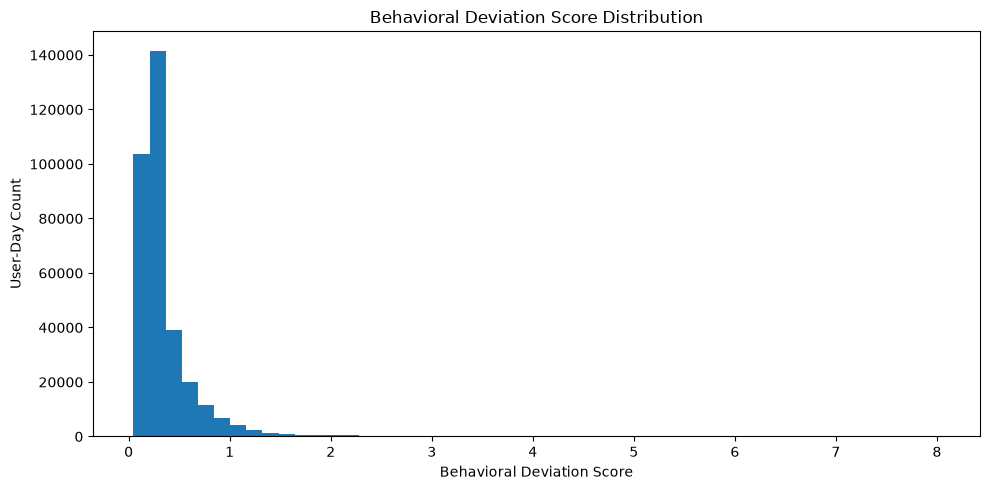

In [4]:
plt.figure(figsize=(10, 5))
df["behavioral_deviation_score"].plot(kind="hist", bins=50)
plt.title("Behavioral Deviation Score Distribution")
plt.xlabel("Behavioral Deviation Score")
plt.ylabel("User-Day Count")
plt.tight_layout()
plt.show()

In [6]:
role_behavior = (
    df.groupby("Role")["behavioral_deviation_score"]
    .agg(["mean", "median", "max", "count"])
    .sort_values("mean", ascending=False)
)

display(role_behavior)

,mean,median,max,count
Role,,,,
IT Admin,0.512272,0.430522,3.177162,4238
Of Council,0.447177,0.378353,3.912867,2537
Loading Dock,0.418942,0.276929,3.929848,5127
Project Manager,0.414284,0.302639,4.763439,9816
Janitor,0.409658,0.319718,4.211093,9323
Unknown,0.374195,0.276670,3.331084,691
Tradesman,0.361623,0.269371,5.992434,47848
VP,0.359513,0.272796,3.568689,4140
Security,0.359108,0.264023,4.421380,14267


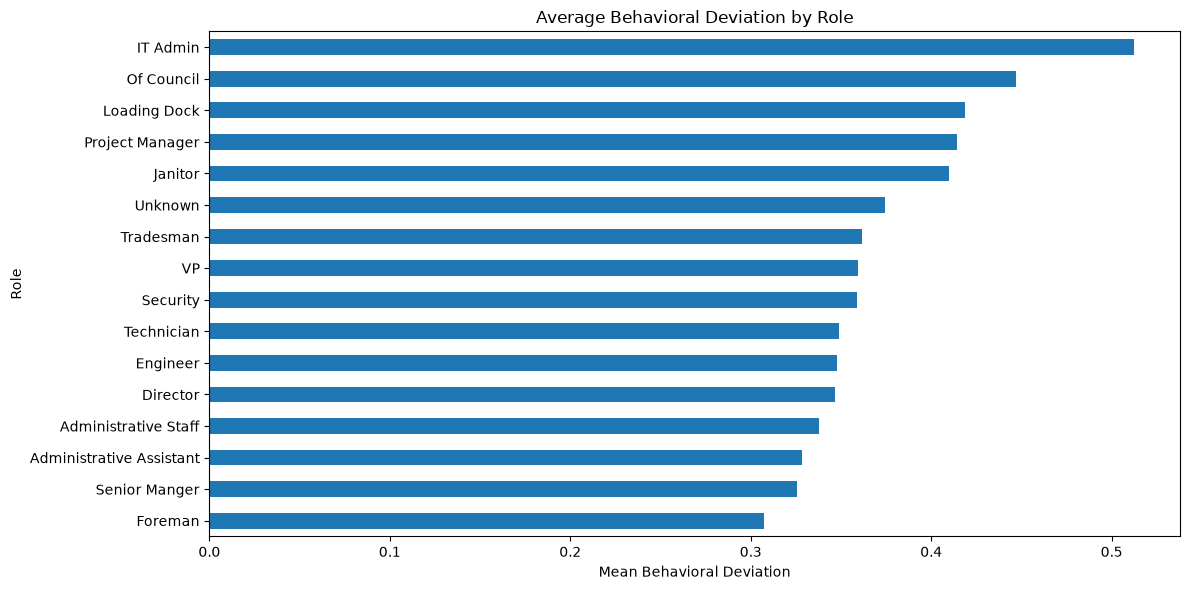

In [7]:
plt.figure(figsize=(12, 6))
role_behavior["mean"].sort_values().plot(kind="barh")
plt.title("Average Behavioral Deviation by Role")
plt.xlabel("Mean Behavioral Deviation")
plt.tight_layout()
plt.show()

In [9]:
comparison = df[
    [
        "user_id",
        "day",
        "Role",
        "personal_anomaly_strength",
        "role_anomaly_strength",
        "behavioral_deviation_score"
    ]
].sort_values(
    "behavioral_deviation_score",
    ascending=False
)

display(comparison.head(20))

,user_id,day,Role,personal_anomaly_strength,role_anomaly_strength,behavioral_deviation_score
155282,JCS0873,2011-02-24,Technician,5.148186,10.000000,8.027090
244129,OYR0801,2011-05-13,Technician,3.895737,10.000000,6.378392
54192,BTW0973,2011-04-27,Tradesman,3.349140,10.000000,5.992434
128756,HAG0649,2011-02-23,Technician,5.170567,6.570882,5.590661
12774,AIB0797,2011-04-27,Administrative Staff,3.175014,10.000000,5.532304
287609,SJH0588,2011-02-24,Foreman,3.993586,8.637606,5.386792
45390,BIR0534,2011-04-27,Administrative Staff,3.364263,9.279111,5.138718
89026,DDK0417,2010-08-07,Administrative Staff,4.175058,7.347659,5.126838
33050,ATJ0284,2010-02-26,Tradesman,5.531274,3.936912,5.052966
11382,AGW0182,2011-04-13,Administrative Assistant,4.080039,7.271687,5.037534
